In [19]:
import pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy import stats

url = "https://raw.githubusercontent.com/nkmwicz/worldcup2018data/refs/heads/main/cleaned_events_world_cup2018.csv"
# https://raw.githubusercontent.com/nkmwicz/worldcup2018data/refs/
# heads/main/cleaned_events_world_cup2018.csv
df = pd.read_csv(url)
df.head(1)

,eventId,subEventName,tags,playerId,matchId,eventName,teamId,matchPeriod,eventSec,subEventId,id,x1,y1,x2,y2
0,8,Simple pass,['Accurate'],Mohammad Ibrahim Al Sahlawi,"Russia - Saudi Arabia, 5 - 0",Pass,Saudi Arabia,1H,1.656214,Simple pass,258612104,50,50,35.0,53.0


In [20]:
df["subEventName"].unique()


<StringArray>
[            'Simple pass',               'High pass',
                'Air duel',   'Ground attacking duel',
   'Ground defending duel',                'Throw in',
                    'Foul',               'Free Kick',
               'Clearance',                   'Touch',
  'Ground loose ball duel',                  'Corner',
               'Head pass',                  'Launch',
            'Acceleration',                    'Shot',
              'Smart pass',                   'Cross',
                'Reflexes',                       nan,
               'Hand pass',               'Goal kick',
         'Free kick cross',               'Hand foul',
            'Save attempt',          'Free kick shot',
 'Goalkeeper leaving line',                 'Penalty',
          'Late card foul',            'Violent Foul',
                 'Protest',        'Out of game foul',
          'Time lost foul',              'Simulation']
Length: 34, dtype: str

In [21]:
df['eventName'].unique()

<StringArray>
[                   'Pass',                    'Duel',
               'Free Kick',                    'Foul',
      'Others on the ball',                    'Shot',
            'Save attempt',                 'Offside',
 'Goalkeeper leaving line']
Length: 9, dtype: str

In [22]:
df['tags'].nunique()

490

In [23]:
import ast

df['tags'] = df['tags'].apply(ast.literal_eval)

In [24]:
unique_tags = list({tag for lst in df['tags'] for tag in lst})
unique_tags

['Position: Goal center right',
 'Free space right',
 'Position: Post high left',
 'Opportunity',
 'Key pass',
 'Second yellow card',
 'High',
 'Red card',
 'Position: Out low right',
 'Blocked',
 'Won',
 'Position: Goal low right',
 'Position: Post center left',
 'Position: Out high left',
 'Yellow card',
 'Position: Goal center left',
 'Lost',
 'Position: Goal center',
 'Position: Goal high left',
 'Neutral',
 'Anticipated',
 'Position: Goal low center',
 'Position: Post center right',
 'Assist',
 'Interception',
 'Not accurate',
 'Goal',
 'Position: Goal high right',
 'Position: Post low right',
 'Right foot',
 'Position: Out high center',
 'Position: Post low left',
 'Accurate',
 'Through',
 'Indirect',
 'Missed ball',
 'Take on right',
 'Feint',
 'Position: Post high right',
 'Position: Out center right',
 'Left foot',
 'Head/body',
 'Counter attack',
 'Free space left',
 'Position: Goal low left',
 'Sliding tackle',
 'Position: Out high right',
 'Dangerous ball lost',
 'Anticipat

In [25]:
df['is_pass'] = (df['eventName'] =='Pass').astype(int)
df['is_shot'] = (df['eventName'] == 'Shot').astype(int)
df.head(1)

,eventId,subEventName,tags,playerId,matchId,eventName,teamId,matchPeriod,eventSec,subEventId,id,x1,y1,x2,y2,is_pass,is_shot
0,8,Simple pass,[Accurate],Mohammad Ibrahim Al Sahlawi,"Russia - Saudi Arabia, 5 - 0",Pass,Saudi Arabia,1H,1.656214,Simple pass,258612104,50,50,35.0,53.0,1,0


In [28]:
df['is_acc_pass'] = df.apply(lambda row: (row['is_pass'] == 1) and ("Accurate" in row['tags']), axis=1).astype(int)
df['is_goal'] = df.apply(lambda row: (row['is_shot'] == 1) and ("Goal" in row['tags']), axis=1).astype(int)

df.head(1)

,eventId,subEventName,tags,playerId,matchId,eventName,teamId,matchPeriod,eventSec,subEventId,id,x1,y1,x2,y2,is_pass,is_shot,is_acc_pass,is_goal
0,8,Simple pass,[Accurate],Mohammad Ibrahim Al Sahlawi,"Russia - Saudi Arabia, 5 - 0",Pass,Saudi Arabia,1H,1.656214,Simple pass,258612104,50,50,35.0,53.0,1,0,1,0


In [29]:
grp_df = df.groupby(['teamId', 'matchId']).agg(
    passes=("is_pass", "sum"),
    acc_passes=("is_acc_pass", "sum"),
    shots=("is_shot", "sum"),
    goals=("is_goal", "sum"),
).reset_index()
grp_df

,teamId,matchId,passes,acc_passes,shots,goals
0,Argentina,"Argentina - Croatia, 0 - 3",476,393,10,0
1,Argentina,"Argentina - Iceland, 1 - 1",744,675,22,1
2,Argentina,"France - Argentina, 4 - 3",486,420,9,3
3,Argentina,"Nigeria - Argentina, 1 - 2",545,458,6,2
4,Australia,"Australia - Peru, 0 - 2",512,446,11,0
...,...,...,...,...,...,...
123,Uruguay,"Egypt - Uruguay, 0 - 1",579,499,11,1
124,Uruguay,"Uruguay - France, 0 - 2",304,227,9,0
125,Uruguay,"Uruguay - Portugal, 2 - 1",238,185,6,2
126,Uruguay,"Uruguay - Russia, 3 - 0",466,405,12,1


Text(0.5, 0.98, 'Good stuff')

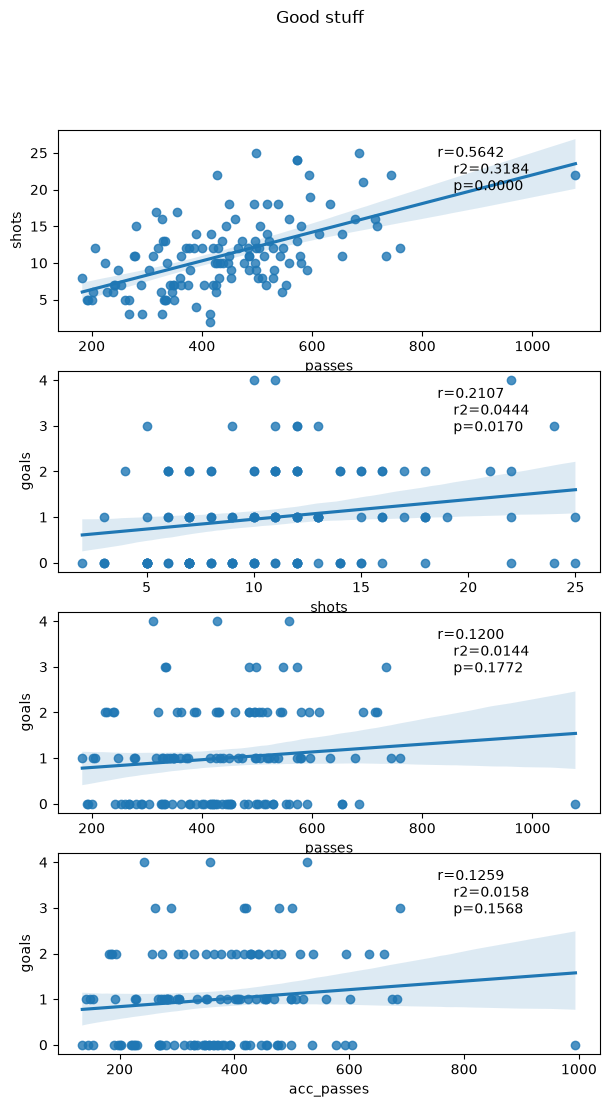

In [41]:
# vars = [(ind, dep)]
vars = [
    ("passes", "shots"),
    ("shots", "goals"),
    ("passes", "goals"),
    ("acc_passes", "goals")
]

fig, axes = plt.subplots(nrows=4, figsize=(7, 12))

for idx, (ind, dep) in enumerate(vars):
    ax = axes[idx]
    r, p = stats.pearsonr(grp_df[ind], grp_df[dep])
    r2 = r**2
    text = f"""r={r:.4f}
    r2={r2:.4f}
    p={p:.4f}"""
    regplot = sns.regplot(data=grp_df, x=ind, y=dep, ax=ax)
    regplot.text(0.7, 0.7, text, transform=regplot.transAxes)
fig.suptitle("Good stuff")
